# Bay Area housing trends, 2000–2025
Compare typical home values and relative house price growth across the nine Bay Area counties. Run this notebook from its folder, placed beside the repository's `cleaned_outputs/` folder. Requires pandas and Matplotlib.

ZHVI is the annual mean of monthly Zillow typical home values in nominal USD. Contra Costa's 2007 estimate uses 11 months because February is missing. The line chart marks this observation with an open circle. FHFA HPI is the annual county all-transactions developmental index rebased to 2000 = 100. Its percentage change measures growth from each county's own baseline.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
import pandas as pd

source_name = "bay_area_county_housing_combined_2000_2025.csv"
source = Path("../cleaned_outputs") / source_name
housing = pd.read_csv(source)
assert not housing.duplicated(["COUNTY", "YEAR"]).any()
assert housing["COUNTY"].nunique() == 9
assert housing.groupby("COUNTY")["YEAR"].apply(lambda years: set(years) == set(range(2000, 2026))).all()

zhvi = "ZHVI_AVAILABLE_MONTH_MEAN_USD"
hpi = "FHFA_HPI_2000_BASE"
assert housing[[zhvi, hpi]].notna().all().all()
figures = Path("figures")
figures.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})


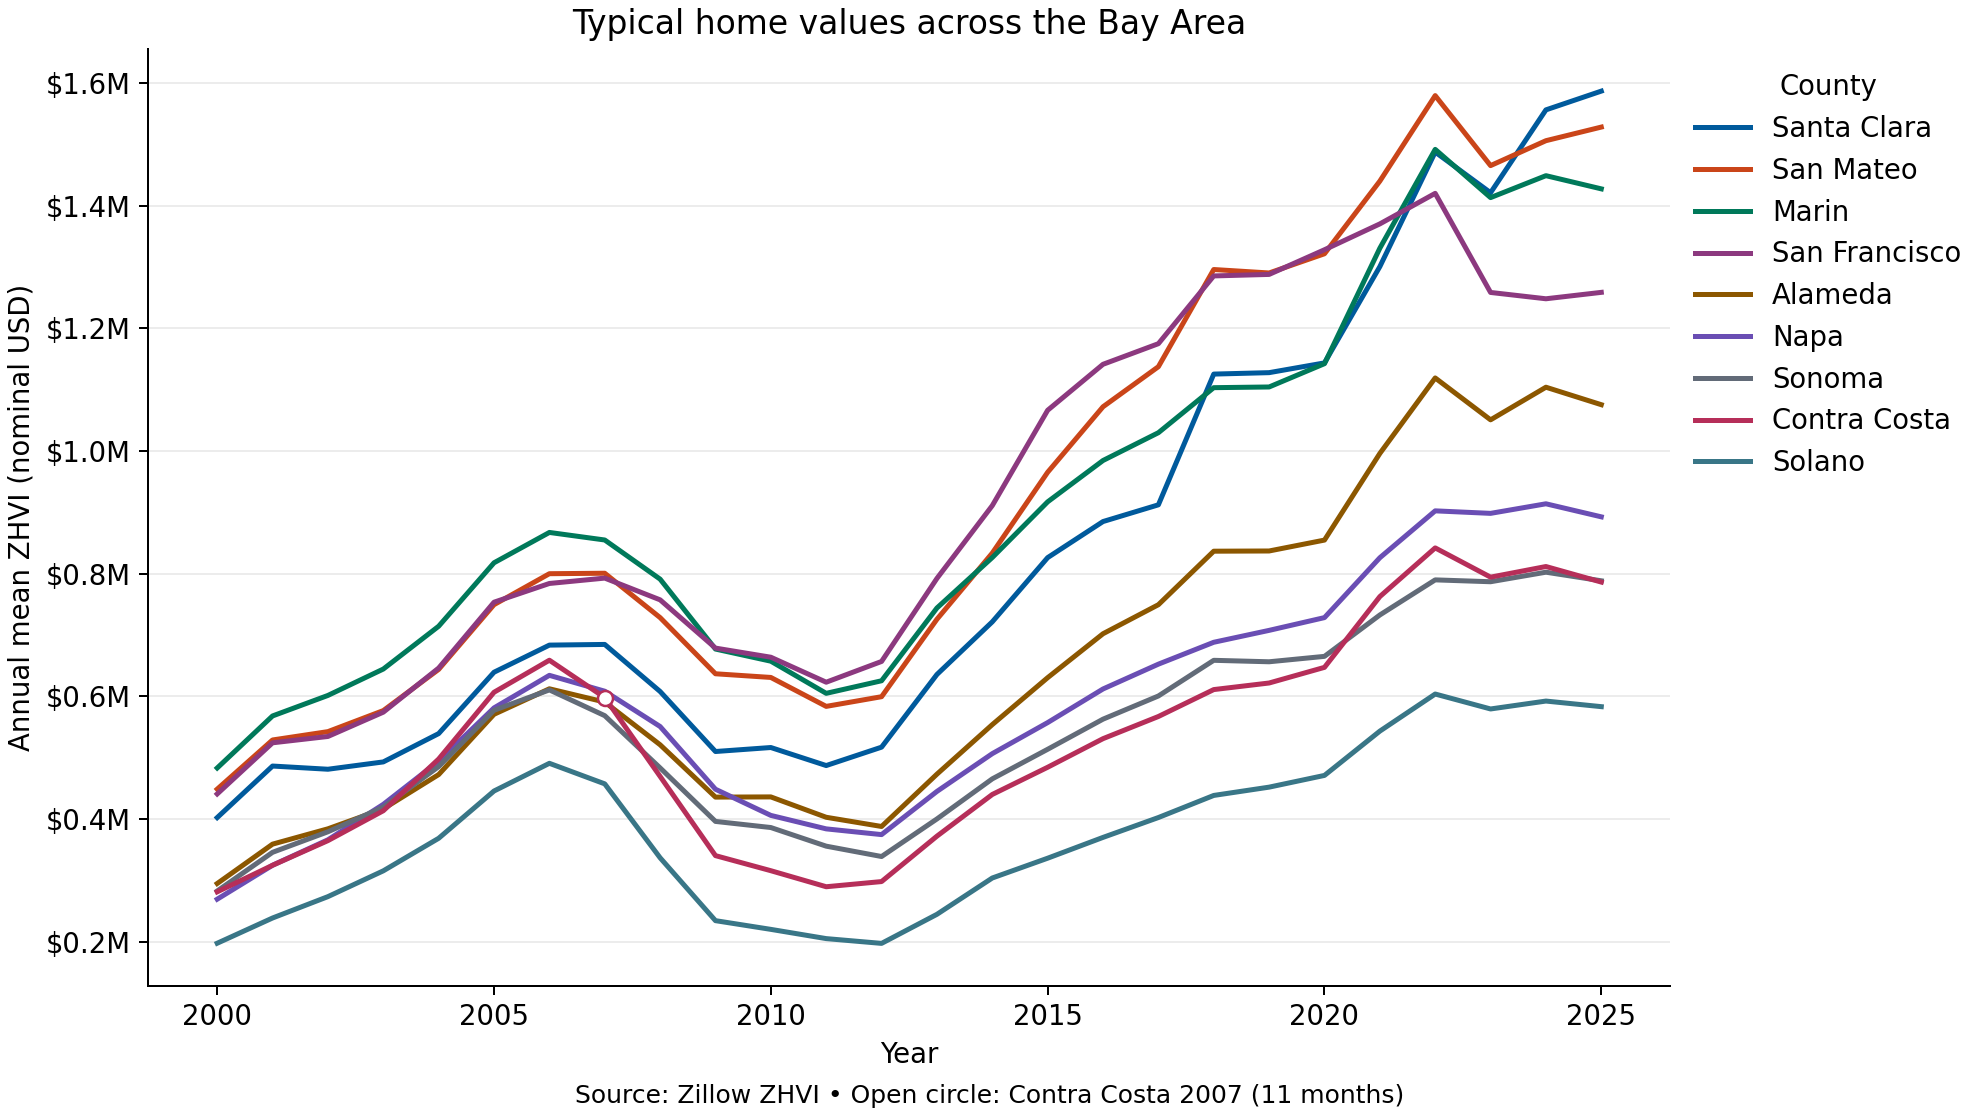

In [2]:
values = housing.pivot(index="YEAR", columns="COUNTY", values=zhvi)
order = values.loc[2025].sort_values(ascending=False).index
colors = ["#005a9c", "#ca4519", "#00795a", "#8c397f", "#8c5700",
          "#6a4eb4", "#626b78", "#b62e59", "#397687"]

fig, ax = plt.subplots(figsize=(11, 6.2), layout="constrained")
for county, color in zip(order, colors):
    ax.plot(values.index, values[county], color=color, label=county, linewidth=2)
    partial = housing.loc[housing["COUNTY"].eq(county) & housing["ZHVI_MONTHS_OBSERVED"].lt(12)]
    ax.scatter(partial["YEAR"], partial[zhvi], facecolors="white", edgecolors=color, zorder=4)
ax.set(title="Typical home values across the Bay Area", xlabel="Year", ylabel="Annual mean ZHVI (nominal USD)")
ax.set_xticks(range(2000, 2026, 5))
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"${value / 1e6:.1f}M"))
ax.grid(axis="y", alpha=.23)
ax.legend(title="County", loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
fig.supxlabel("Source: Zillow ZHVI • Open circle: Contra Costa 2007 (11 months)", fontsize=10)
fig.savefig(figures / "zhvi_county_trends.png", dpi=180, facecolor="white")
plt.show()


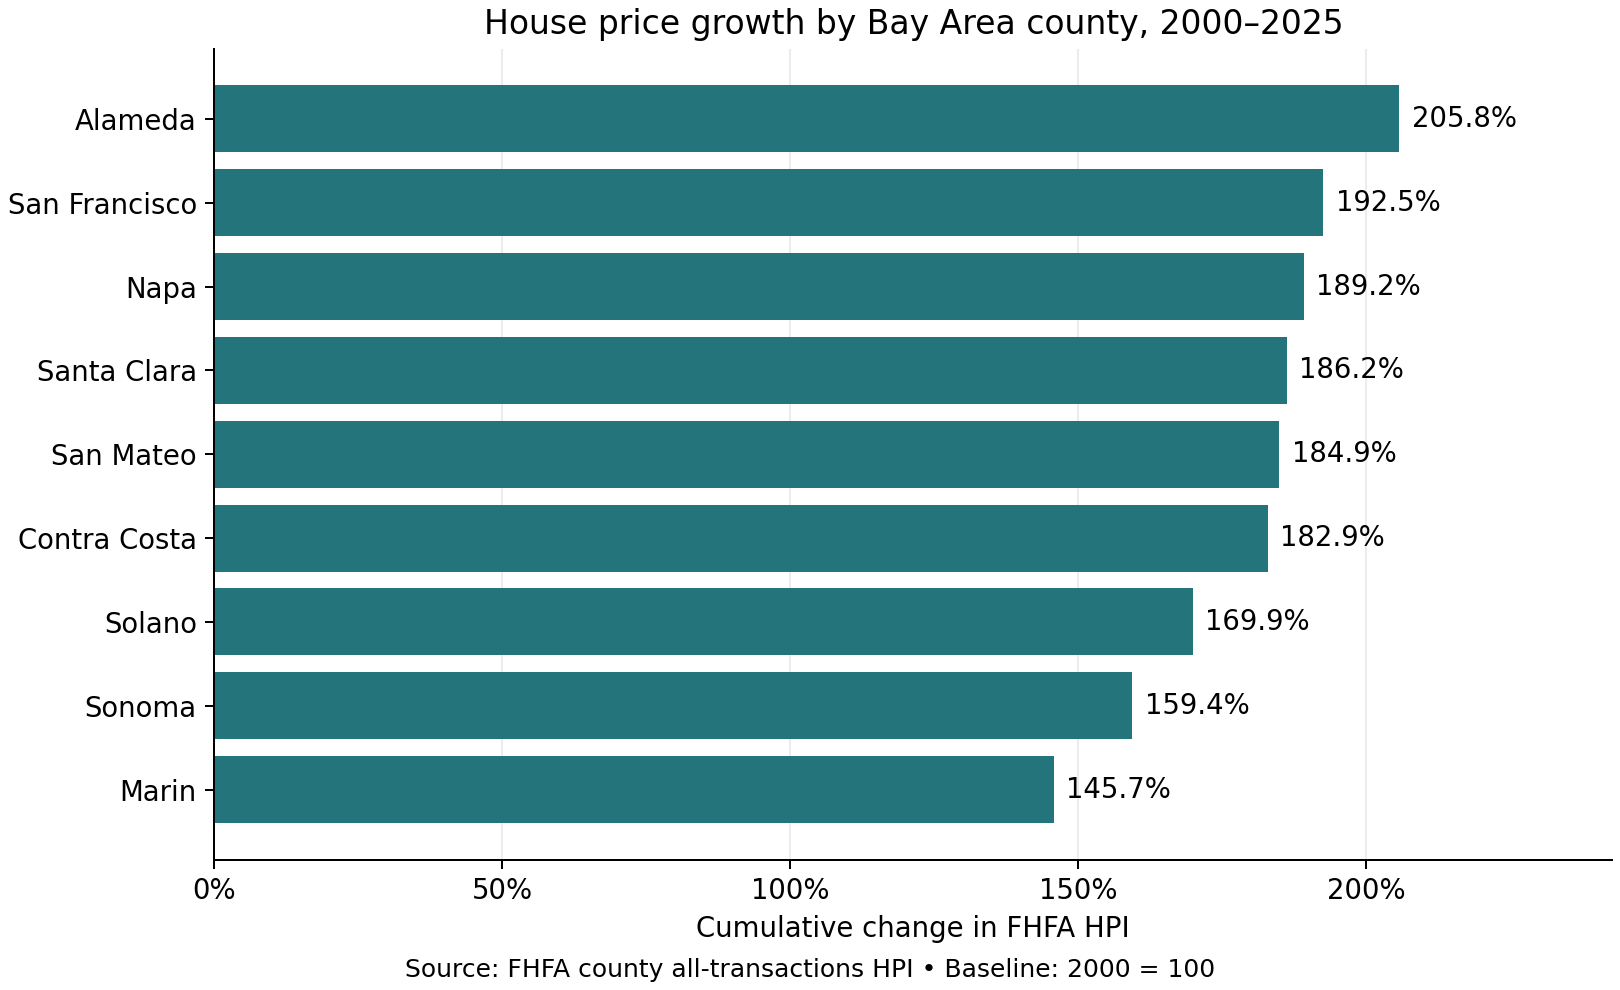

In [3]:
index = housing.pivot(index="YEAR", columns="COUNTY", values=hpi)
growth = ((index.loc[2025] / index.loc[2000] - 1) * 100).sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5), layout="constrained")
bars = ax.barh(growth.index, growth, color="#23757b")
ax.bar_label(bars, labels=[f"{value:.1f}%" for value in growth], padding=5)
ax.set(title="House price growth by Bay Area county, 2000–2025", xlabel="Cumulative change in FHFA HPI")
ax.set_xlim(0, growth.max() * 1.18)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=.23)
fig.supxlabel("Source: FHFA county all-transactions HPI • Baseline: 2000 = 100", fontsize=10)
fig.savefig(figures / "fhfa_cumulative_growth.png", dpi=180, facecolor="white")
plt.show()


In [4]:
periods = {"2006–2011": (2006, 2011), "2019–2022": (2019, 2022), "2022–2025": (2022, 2025)}
summary = pd.DataFrame({"2025 ZHVI (USD)": values.loc[2025], "2000–2025 FHFA growth (%)": growth})
for period, (start, end) in periods.items():
    summary[f"{period} ZHVI change (%)"] = (values.loc[end] / values.loc[start] - 1) * 100
summary.loc[order].round(1)


               2025 ZHVI (USD)  2000–2025 FHFA growth (%)  2006–2011 ZHVI change (%)  2019–2022 ZHVI change (%)  2022–2025 ZHVI change (%)
COUNTY                                                                                                                                    
Santa Clara          1586595.2                      186.2                      -28.7                       31.9                        6.7
San Mateo            1527959.6                      184.9                      -27.0                       22.4                       -3.2
Marin                1427236.9                      145.7                      -30.3                       35.1                       -4.3
San Francisco        1258505.6                      192.5                      -20.5                       10.3                      -11.4
Alameda              1075370.6                      205.8                      -34.2                       33.7                       -3.9
Napa                  89253

# Bay Area housing findings

- **2025 home values varied substantially across counties.** Santa Clara had the highest annual typical home value at $1.59 million, about 2.7 times Solano's $583,082, the lowest among the nine counties.
- **Typical home values fell in all nine counties between 2006 and 2011.** Solano recorded the steepest decline (-58.2%), while San Francisco recorded the smallest decline (-20.5%).
- **County trends diverged between 2022 and 2025.** Santa Clara was the only county where typical home value rose (+6.7%). San Francisco fell by 11.4%, the largest decline.
- **FHFA's index rose across all nine counties from 2000 to 2025.** Alameda recorded the largest cumulative increase (+205.8%) and Marin the smallest (+145.7%).

Dollar values use annual averages of monthly Zillow ZHVI in nominal USD. Contra Costa's 2007 average uses 11 months. FHFA changes use the annual county all-transactions index with 2000 as the baseline. Both charts describe county-level trends.
